# 02 Baselines and models (validation only)

Do not open any test result in this notebook. The test set stays untouched until Week 3.

In [6]:
import json, os, sys
from pathlib import Path

# Work from the repository root whether the notebook is opened from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cfg = json.load(open("configs/dataset.json"))
OUT = Path("results/data_quality"); OUT.mkdir(parents=True, exist_ok=True)
cfg

{'dataset_name': 'PEMS-BAY',
 'speed_file': 'data/raw/pems-bay.h5',
 'speed_key': None,
 'sensor_locations_file': 'data/raw/graph_sensor_locations_bay.csv',
 'min_coverage': 0.95,
 'min_readings_per_hour': 9,
 'n_segments': 8,
 'n_neighbours': 3,
 'segments': ['401507',
  '404554',
  '400414',
  '400100',
  '402287',
  '413878',
  '407157',
  '407176'],
 'city_name': 'San Francisco Bay Area',
 'city_lat': None,
 'city_lon': None,
 'timezone': 'America/Los_Angeles',
 'holiday_country': 'US',
 'holiday_subdiv': 'CA'}

## Split overview

In [7]:
split = json.load(open("configs/split.json"))
pd.DataFrame(split["splits"]).T

,rows,start,end
train,20584,2017-01-02 00:00:00,2017-04-20 06:00:00
val,6848,2017-04-20 09:00:00,2017-05-26 00:00:00
test,6872,2017-05-26 03:00:00,2017-06-30 21:00:00


## Baselines on validation

In [8]:
from baselines import hour_of_week_predict, persistence_predict
train = pd.read_parquet("data/processed/train.parquet")
val = pd.read_parquet("data/processed/val.parquet")
mae = lambda y, p: float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
print("persistence  val MAE:", round(mae(val["target_2h"], persistence_predict(val)), 3))
print("hour-of-week val MAE:", round(mae(val["target_2h"], hour_of_week_predict(train, val)), 3))

persistence  val MAE: 5.366
hour-of-week val MAE: 2.342


## Candidate models on validation (after running `python src/03_train_select.py`)

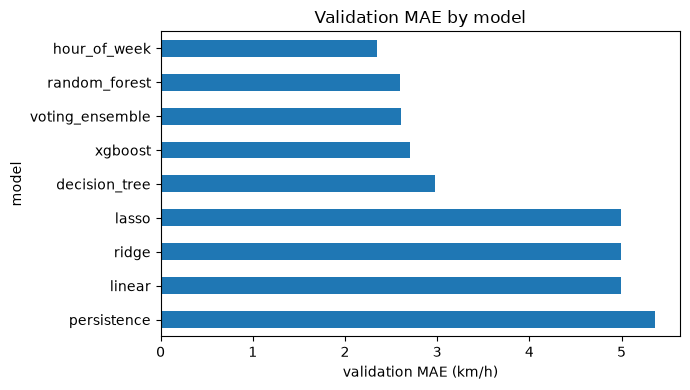

,model,val_mae
0,hour_of_week,2.342
1,random_forest,2.595
2,voting_ensemble,2.612
3,xgboost,2.710
4,decision_tree,2.972
5,lasso,4.993
6,ridge,4.999
7,linear,4.999
8,persistence,5.366


In [9]:
vm = pd.read_csv("results/validation_metrics.csv").sort_values("val_mae")
ax = vm.plot.barh(x="model", y="val_mae", legend=False, figsize=(7, 4)); ax.invert_yaxis()
ax.set_xlabel("validation MAE (km/h)"); ax.set_title("Validation MAE by model")
plt.tight_layout(); plt.savefig("results/val_model_comparison.png", dpi=150); plt.show()
vm.round(3)

## Tuned settings

In [10]:
final = json.load(open("configs/final_model.json"))
print("Selected on validation:", final["selected"], "| ensemble members:", final["ensemble_members"])
pd.Series({k: str(v) for k, v in final["params"].items()}, name="best params")

Selected on validation: random_forest | ensemble members: ['random_forest', 'xgboost', 'decision_tree']


linear                                                     default
ridge                                          {'ridge__alpha': 1}
lasso                                        {'lasso__alpha': 0.1}
decision_tree              {'decisiontreeregressor__max_depth': 8}
random_forest             {'randomforestregressor__max_depth': 12}
xgboost          {'xgbregressor__learning_rate': 0.05, 'xgbregr...
Name: best params, dtype: object

## Notes (Saw / Means)

Features: the first run used 15 features. I then added `lag_168h` (speed at the same hour last week, past only) and retrained. Numbers below are from the second run.

- **Saw:** hour_of_week 2.342 is still the best of all. **Means:** the weekly rhythm (hour + weekday) already explains most of the speed. No trained model beat it on validation, so this is an honest finding, not a failure.
- **Saw:** voting_ensemble 2.551 is the best trained model (0.21 km/h worse than hour_of_week); random_forest 2.573 is close behind. **Means:** the ensemble is selected on validation MAE. Adding `lag_168h` moved RF from 2.595 to 2.573, xgboost from 2.710 to 2.615 and the ensemble from 2.612 to 2.551, so it helped a little, but not enough to pass the weekly baseline.
- **Saw:** decision_tree 2.907. **Means:** one tree fits the rush-hour pattern less well than many trees averaged.
- **Saw:** linear 4.977, ridge 4.977, lasso 4.950, about 7% better than persistence 5.366. **Means:** a straight-line model cannot express "weekday 8 am = slow". Regularisation does not fix this.
- **Saw:** persistence 5.366 is the worst. **Means:** speed now is a poor guide to speed 2 h later, especially at rush-hour start and end.
- **Not done:** the test set was not opened. The model is not frozen yet; that happens after the ensemble decision.
